In [8]:
from pathlib import Path
import random
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

Matplotlib is building the font cache; this may take a moment.


In [9]:
dataset_root = Path.cwd().parent / "data" / "raw" / "bdd100k"

train_images = sorted((dataset_root / "train" / "images").glob("*.jpg"))
val_images = sorted((dataset_root / "val" / "images").glob("*.jpg"))
test_images = sorted((dataset_root / "test").glob("*.jpg"))

print(f"Training images:   {len(train_images):,}")
print(f"Validation images: {len(val_images):,}")
print(f"Testing images:    {len(test_images):,}")

random.seed(42)

Training images:   70,000
Validation images: 10,000
Testing images:    20,000


(1280, 720)
RGB
JPEG


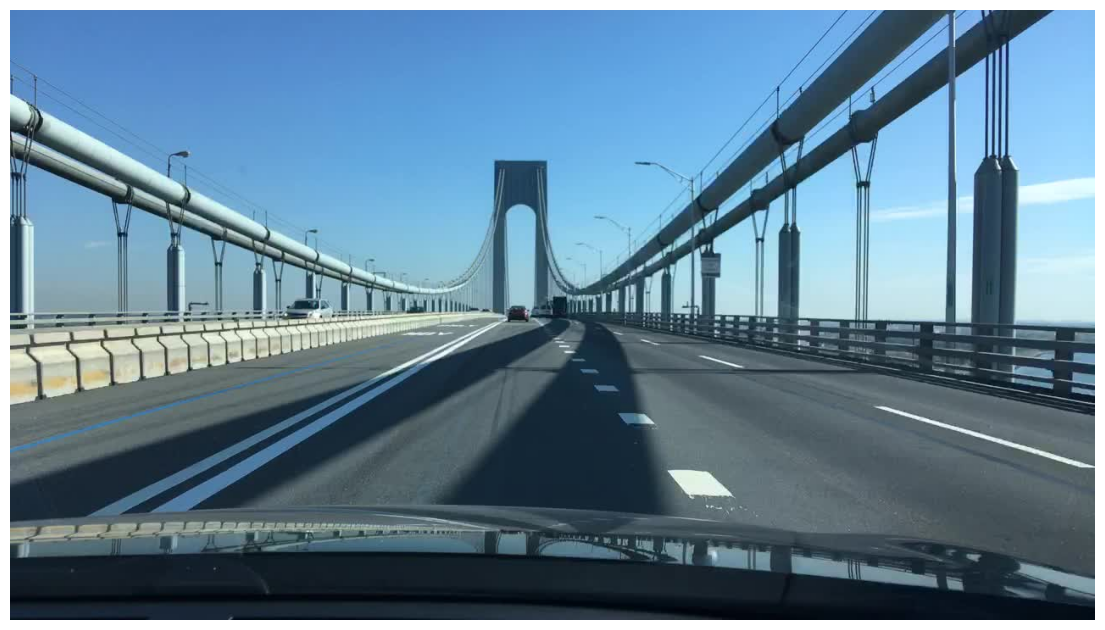

In [10]:
image_path = random.choice(train_images)

image = Image.open(image_path)

print(image.size)
print(image.mode)
print(image.format)

plt.figure(figsize=(14, 8))
plt.imshow(image)
plt.axis("off")
plt.show()

In [11]:
image_array = np.array(image)

print("Shape:", image_array.shape)
print("Data type:", image_array.dtype)
print("Minimum:", image_array.min())
print("Maximum:", image_array.max())
print("Memory (MB):", image_array.nbytes / 1024**2)

Shape: (720, 1280, 3)
Data type: uint8
Minimum: 0
Maximum: 255
Memory (MB): 2.63671875


In [12]:
image_array

array([[[ 76, 127, 192],
        [ 76, 127, 192],
        [ 76, 127, 192],
        ...,
        [125, 186, 241],
        [125, 186, 241],
        [125, 186, 241]],

       [[ 76, 127, 192],
        [ 76, 127, 192],
        [ 76, 127, 192],
        ...,
        [125, 186, 241],
        [125, 186, 241],
        [125, 186, 241]],

       [[ 76, 127, 192],
        [ 76, 127, 192],
        [ 76, 127, 192],
        ...,
        [125, 186, 241],
        [125, 186, 241],
        [125, 186, 241]],

       ...,

       [[ 15,  29,  42],
        [ 15,  29,  40],
        [ 15,  29,  42],
        ...,
        [  2,  12,  22],
        [  2,  12,  22],
        [  2,  12,  22]],

       [[  8,  22,  33],
        [  8,  22,  31],
        [  8,  22,  33],
        ...,
        [  2,  12,  22],
        [  2,  12,  22],
        [  2,  12,  22]],

       [[  3,  17,  26],
        [  3,  17,  26],
        [  3,  17,  26],
        ...,
        [  2,  12,  22],
        [  2,  12,  22],
        [  2,  12,  22]]

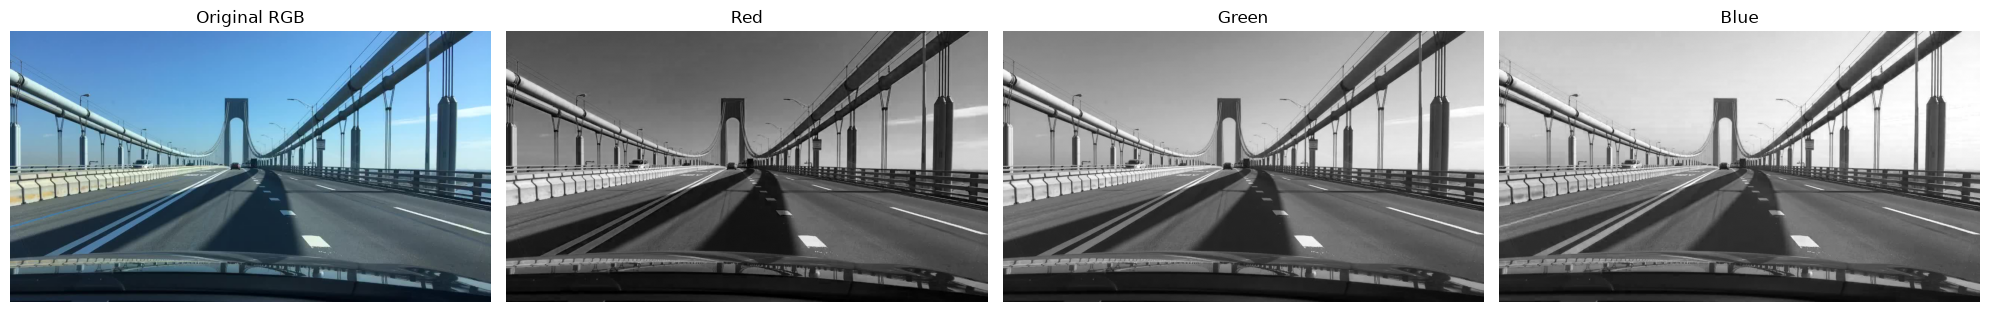

In [ ]:
# Visualizing individual colour channels
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(image_array)
axes[0].set_title("Original RGB")

for i, channel in enumerate(["Red", "Green", "Blue"]):
    axes[i + 1].imshow(image_array[:, :, i], cmap="gray")
    axes[i + 1].set_title(channel)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

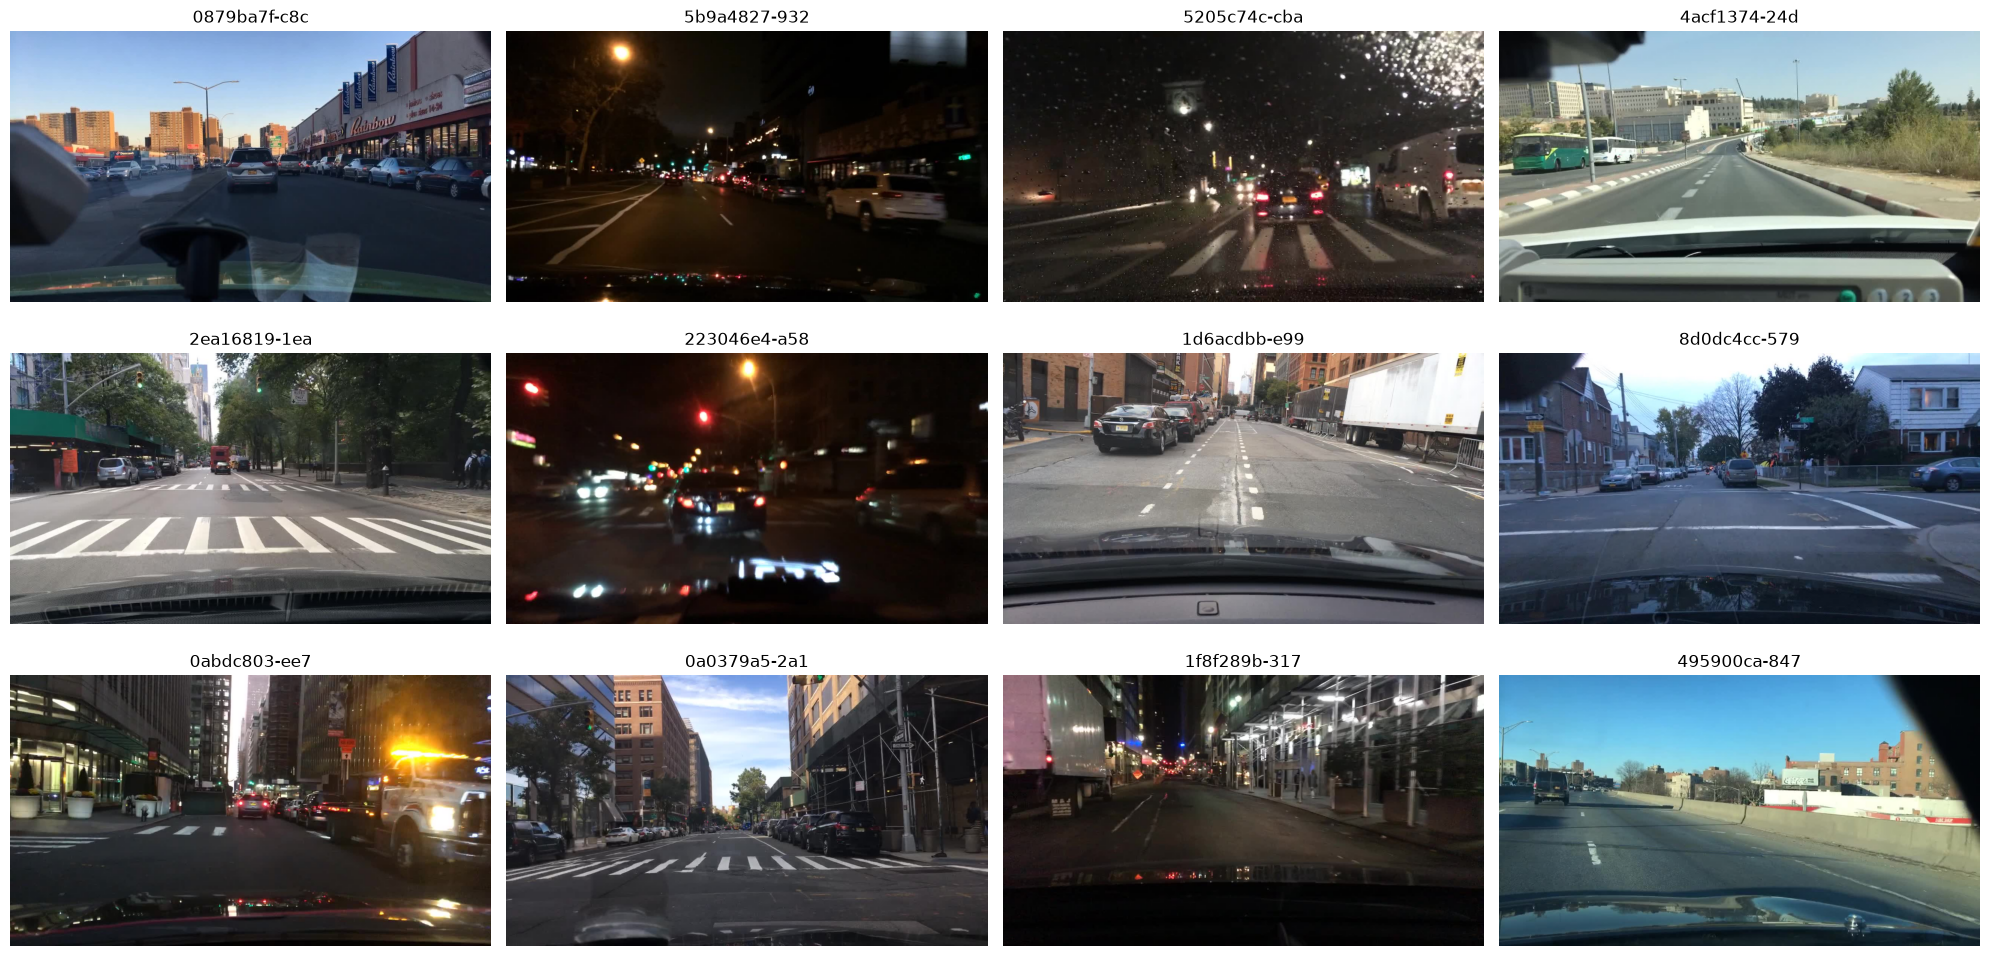

In [ ]:
# a random sample of images from the training set
# observe how many images have liense plates in them
sample_images = random.sample(train_images, 12)

fig, axes = plt.subplots(3, 4, figsize=(20, 10))

for ax, path in zip(axes.flat, sample_images):
    with Image.open(path) as img:
        ax.imshow(img)

    ax.set_title(path.name[:12])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [15]:
# Image resolution and file size distribution
records = []

for path in random.sample(train_images, 1000):
    with Image.open(path) as img:
        records.append({
            "filename": path.name,
            "width": img.width,
            "height": img.height,
            "mode": img.mode,
            "aspect_ratio": img.width / img.height,
            "file_size_kb": path.stat().st_size / 1024
        })

image_stats = pd.DataFrame(records)

image_stats.head()

,filename,width,height,mode,aspect_ratio,file_size_kb
0,4e0b0e1d-c8fdfeed.jpg,1280,720,RGB,1.777778,32.650391
1,a8cbac60-a4234e6c.jpg,1280,720,RGB,1.777778,49.072266
2,08ec5fe9-16c339b7.jpg,1280,720,RGB,1.777778,55.397461
3,427e57b2-98fe522d.jpg,1280,720,RGB,1.777778,67.286133
4,8c35d373-b2519bb0.jpg,1280,720,RGB,1.777778,30.368164


In [ ]:
image_stats.groupby(["width", "height"]).size()
# establish all are having: the following dimensions 1280   720        

width  height
1280   720       1000
dtype: int64

In [17]:
image_stats.describe()

,width,height,aspect_ratio,file_size_kb
count,1000.0,1000.0,1.000000e+03,1000.000000
mean,1280.0,720.0,1.777778e+00,56.036999
std,0.0,0.0,6.664671e-16,18.790642
min,1280.0,720.0,1.777778e+00,22.065430
25%,1280.0,720.0,1.777778e+00,39.906494
50%,1280.0,720.0,1.777778e+00,54.285645
75%,1280.0,720.0,1.777778e+00,70.793213
max,1280.0,720.0,1.777778e+00,117.925781


# Existing BDD100K Annotation Exploration

In [23]:
train_annotation_file = list((dataset_root / "train" / "annotations").glob("*.json"))[0]
train_annotation_file

WindowsPath('c:/Users/aarish.tickoo/workspace/traffic-pii-masking/data/raw/bdd100k/train/annotations/bdd100k_labels_images_train.json')

In [26]:
with open(train_annotation_file, "r") as f:
    train_annotations = json.load(f)

print(type(train_annotations))
print(len(train_annotations))
print(train_annotations[0])

<class 'list'>
69863
{'name': '0000f77c-6257be58.jpg', 'attributes': {'weather': 'clear', 'scene': 'city street', 'timeofday': 'daytime'}, 'timestamp': 10000, 'labels': [{'category': 'traffic light', 'attributes': {'occluded': False, 'truncated': False, 'trafficLightColor': 'green'}, 'manualShape': True, 'manualAttributes': True, 'box2d': {'x1': 1125.902264, 'y1': 133.184488, 'x2': 1156.978645, 'y2': 210.875445}, 'id': 0}, {'category': 'traffic light', 'attributes': {'occluded': False, 'truncated': False, 'trafficLightColor': 'green'}, 'manualShape': True, 'manualAttributes': True, 'box2d': {'x1': 1156.978645, 'y1': 136.637417, 'x2': 1191.50796, 'y2': 210.875443}, 'id': 1}, {'category': 'traffic sign', 'attributes': {'occluded': False, 'truncated': False, 'trafficLightColor': 'none'}, 'manualShape': True, 'manualAttributes': True, 'box2d': {'x1': 1101.731743, 'y1': 211.122087, 'x2': 1170.79037, 'y2': 233.566141}, 'id': 2}, {'category': 'traffic sign', 'attributes': {'occluded': False, 

#### One complete JSON annotation record.

In [ ]:
print(json.dumps(train_annotations[0], indent=2))

{
  "name": "0000f77c-6257be58.jpg",
  "attributes": {
    "weather": "clear",
    "scene": "city street",
    "timeofday": "daytime"
  },
  "timestamp": 10000,
  "labels": [
    {
      "category": "traffic light",
      "attributes": {
        "occluded": false,
        "truncated": false,
        "trafficLightColor": "green"
      },
      "manualShape": true,
      "manualAttributes": true,
      "box2d": {
        "x1": 1125.902264,
        "y1": 133.184488,
        "x2": 1156.978645,
        "y2": 210.875445
      },
      "id": 0
    },
    {
      "category": "traffic light",
      "attributes": {
        "occluded": false,
        "truncated": false,
        "trafficLightColor": "green"
      },
      "manualShape": true,
      "manualAttributes": true,
      "box2d": {
        "x1": 1156.978645,
        "y1": 136.637417,
        "x2": 1191.50796,
        "y2": 210.875443
      },
      "id": 1
    },
    {
      "category": "traffic sign",
      "attributes": {
        "occlu

### An image with existing bounding boxes visualized.

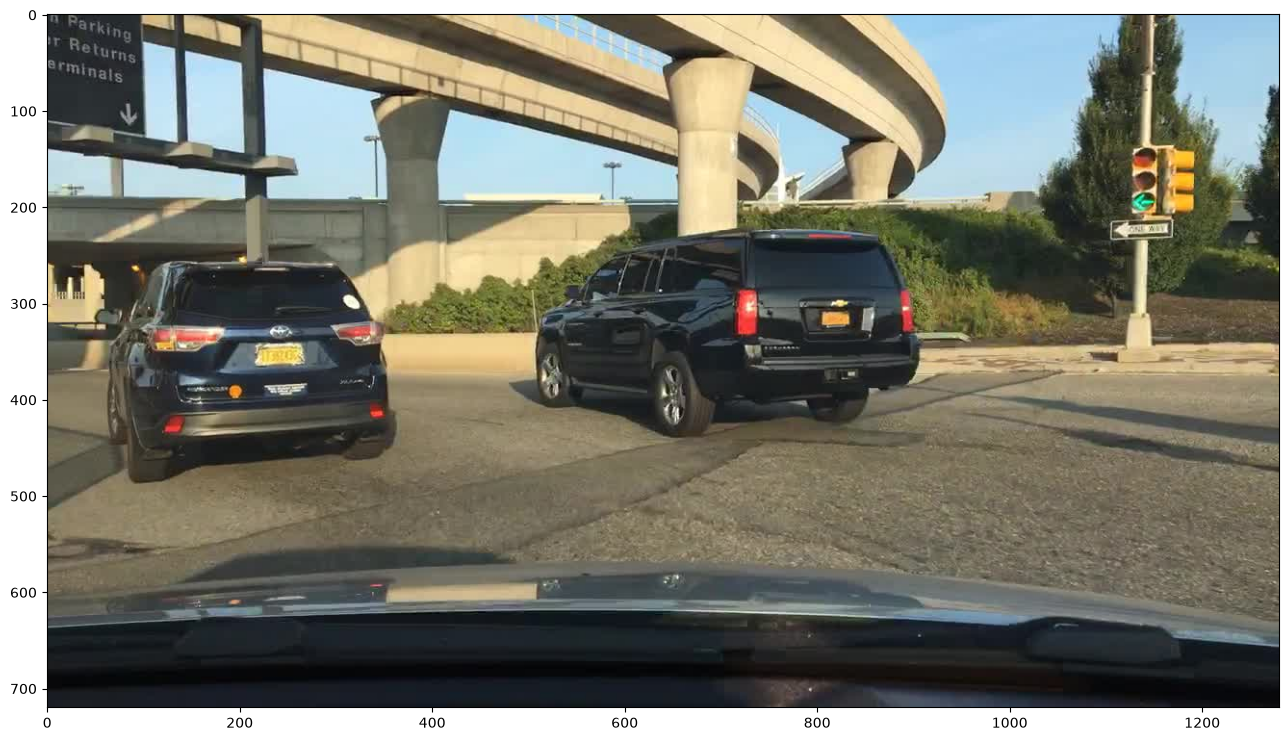

In [27]:
record = train_annotations[0]

image_path = dataset_root / "train" / "images" / record["name"]

image = Image.open(image_path).convert("RGB")

plt.figure(figsize=(16, 9))
plt.imshow(image)
plt.show()

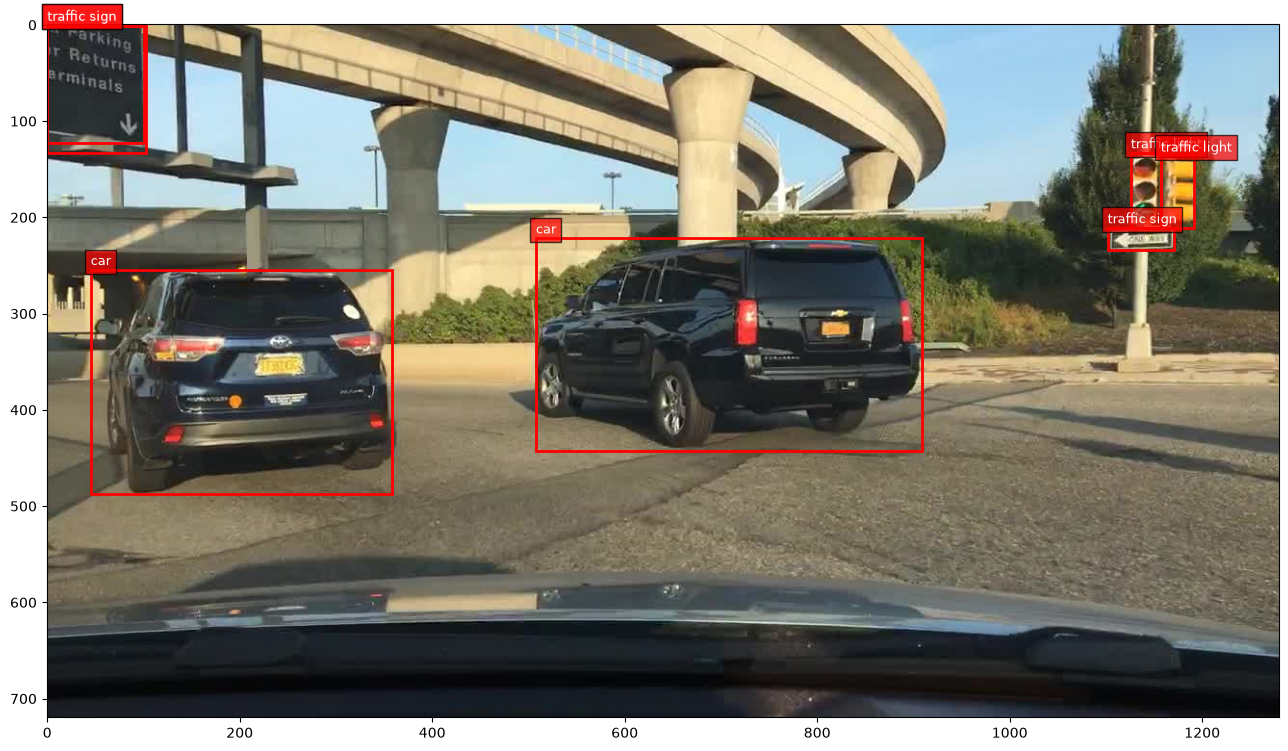

In [ ]:
# visualize bounding boxes 
import matplotlib.patches as patches    

fig, ax = plt.subplots(figsize=(16, 9))

ax.imshow(image)

for obj in record["labels"]:

    if "box2d" not in obj:
        continue

    box = obj["box2d"]

    x1, y1 = box["x1"], box["y1"]
    x2, y2 = box["x2"], box["y2"]

    rectangle = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(rectangle)

    ax.text(
        x1,
        y1 - 5,
        obj["category"],
        color="white",
        fontsize=9,
        bbox={"facecolor": "red", "alpha": 0.7}
    )

plt.show()

### The object category distribution (category of object vs no. of instantces).

In [31]:
from collections import Counter

category_counts = Counter(
    obj["category"]
    for record in train_annotations
    for obj in record.get("labels", [])
)

category_counts

category_df = pd.DataFrame(
    category_counts.items(),
    columns=["category", "count"]
).sort_values("count", ascending=False)

category_df

,category,count
2,car,713211
4,lane,528643
1,traffic sign,239686
0,traffic light,186117
3,drivable area,125723
5,person,91349
7,truck,29971
6,bus,11672
9,bike,7210
8,rider,4517


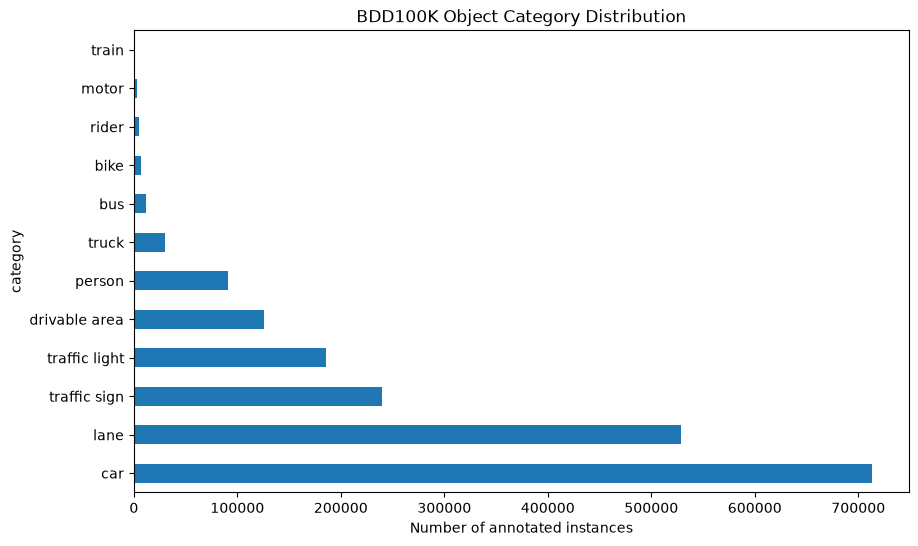

In [32]:
category_df.plot(
    x="category",
    y="count",
    kind="barh",
    figsize=(10, 6),
    legend=False
)

plt.xlabel("Number of annotated instances")
plt.title("BDD100K Object Category Distribution")
plt.show()

In [33]:
# this is our first dataset level finding. How many categories of objects are labelled and how many instances of each category are present in the dataset?

In [34]:
### For now, we will pursue direct detection. However, vehicle crops might become useful later if our model struggles with small licence plates.

### Convert annotations into structured DataFrames

In [ ]:
# Image level dataframe with image_id, weather, scene, timeofday, and object_count
image_records = []

for record in train_annotations:

    attributes = record.get("attributes", {})

    image_records.append({
        "image_id": record["name"],
        "weather": attributes.get("weather"),
        "scene": attributes.get("scene"),
        "timeofday": attributes.get("timeofday"),
        "object_count": len(record.get("labels", []))
    })

images_df = pd.DataFrame(image_records)

images_df.head()

,image_id,weather,scene,timeofday,object_count
0,0000f77c-6257be58.jpg,clear,city street,daytime,11
1,0000f77c-62c2a288.jpg,clear,highway,dawn/dusk,17
2,0000f77c-cb820c98.jpg,clear,residential,dawn/dusk,12
3,0001542f-5ce3cf52.jpg,clear,city street,night,18
4,0001542f-7c670be8.jpg,clear,highway,night,13


In [39]:
images_df.describe(include=["str"])

,image_id,weather,scene,timeofday
count,69863,69863,69863,69863
unique,69863,7,7,4
top,0000f77c-6257be58.jpg,clear,city street,daytime
freq,1,37344,43516,36728


In [40]:
# object level dataframe with image_id, object_id, category, bounding box coordinates, width, height, area, occluded, truncated
object_records = []

for record in train_annotations:

    for obj in record.get("labels", []):

        if "box2d" not in obj:
            continue

        box = obj["box2d"]
        attributes = obj.get("attributes", {})

        width = box["x2"] - box["x1"]
        height = box["y2"] - box["y1"]

        object_records.append({
            "image_id": record["name"],
            "object_id": obj.get("id"),
            "category": obj["category"],
            "x1": box["x1"],
            "y1": box["y1"],
            "x2": box["x2"],
            "y2": box["y2"],
            "width": width,
            "height": height,
            "area": width * height,
            "occluded": attributes.get("occluded"),
            "truncated": attributes.get("truncated")
        })

objects_df = pd.DataFrame(object_records)

objects_df.head()

,image_id,object_id,category,x1,y1,x2,y2,width,height,area,occluded,truncated
0,0000f77c-6257be58.jpg,0,traffic light,1125.902264,133.184488,1156.978645,210.875445,31.076381,77.690957,2414.353780,False,False
1,0000f77c-6257be58.jpg,1,traffic light,1156.978645,136.637417,1191.507960,210.875443,34.529315,74.238026,2563.388185,False,False
2,0000f77c-6257be58.jpg,2,traffic sign,1101.731743,211.122087,1170.790370,233.566141,69.058627,22.444054,1549.955554,False,False
3,0000f77c-6257be58.jpg,3,traffic sign,0.000000,0.246631,100.381647,122.825696,100.381647,122.579065,12304.688432,False,True
4,0000f77c-6257be58.jpg,4,car,45.240919,254.530367,357.805838,487.906215,312.564919,233.375848,72945.103027,False,False


In [41]:
objects_df.describe()

,object_id,x1,y1,x2,y2,width,height,area
count,1.286871e+06,1.286871e+06,1.286871e+06,1.286871e+06,1.286871e+06,1.286871e+06,1.286871e+06,1.286871e+06
mean,9.701904e+05,5.620564e+02,3.011627e+02,6.186523e+02,3.510780e+02,5.659588e+01,4.991536e+01,6.776563e+03
std,5.604050e+05,2.870801e+02,9.352634e+01,2.925408e+02,1.069834e+02,7.569068e+01,6.168860e+01,2.285026e+04
min,0.000000e+00,0.000000e+00,0.000000e+00,1.972998e+00,4.409275e+00,1.066250e-01,1.654980e-01,8.714117e-01
25%,4.848655e+05,3.729372e+02,2.494208e+02,4.208508e+02,2.863433e+02,1.687499e+01,1.713855e+01,3.045992e+02
50%,9.695760e+05,5.652781e+02,3.071248e+02,6.010568e+02,3.503248e+02,2.869834e+01,2.909387e+01,8.173673e+02
75%,1.455574e+06,7.434699e+02,3.605807e+02,7.927870e+02,4.133624e+02,6.040677e+01,5.527958e+01,3.022785e+03
max,1.941226e+06,1.279178e+03,7.155113e+02,1.280000e+03,7.200000e+02,1.279269e+03,7.197735e+02,9.177098e+05


In [43]:
print(images_df.shape)
print(objects_df.shape)

(69863, 5)
(1286871, 12)


### Vehicle statistics

In [44]:
vehicle_categories = [
    "car",
    "truck",
    "bus",
    "motorcycle"
]

vehicles_df = objects_df[
    objects_df["category"].isin(vehicle_categories)
].copy()

vehicles_df.head()  

,image_id,object_id,category,x1,y1,x2,y2,width,height,area,occluded,truncated
4,0000f77c-6257be58.jpg,4,car,45.240919,254.530367,357.805838,487.906215,312.564919,233.375848,72945.103027,False,False
5,0000f77c-6257be58.jpg,5,car,507.827550,221.727518,908.367588,442.715126,400.540038,220.987608,88514.384906,False,False
13,0000f77c-cb820c98.jpg,28,car,581.938239,301.360875,641.319692,350.350574,59.381453,48.989699,2909.079509,False,False
14,0000f77c-cb820c98.jpg,29,car,697.732074,299.876337,722.969191,331.051600,25.237117,31.175263,786.773760,True,False
15,0000f77c-cb820c98.jpg,30,car,715.546509,302.845412,768.989817,344.412429,53.443308,41.567017,2221.478892,True,False


In [45]:
vehicle_counts = (
    vehicles_df
    .groupby("image_id")
    .size()
    .rename("vehicle_count")
    .reset_index()
)

images_df = images_df.merge(
    vehicle_counts,
    on="image_id",
    how="left"
)

images_df["vehicle_count"] = (
    images_df["vehicle_count"].fillna(0).astype(int)
)

images_df.head()

,image_id,weather,scene,timeofday,object_count,vehicle_count
0,0000f77c-6257be58.jpg,clear,city street,daytime,11,2
1,0000f77c-62c2a288.jpg,clear,highway,dawn/dusk,17,0
2,0000f77c-cb820c98.jpg,clear,residential,dawn/dusk,12,7
3,0001542f-5ce3cf52.jpg,clear,city street,night,18,10
4,0001542f-7c670be8.jpg,clear,highway,night,13,3


In [46]:
images_df["vehicle_count"].describe()

count    69863.000000
mean        10.804775
std          6.213331
min          0.000000
25%          6.000000
50%         10.000000
75%         15.000000
max         66.000000
Name: vehicle_count, dtype: float64